# Tarefa 2 — Random Forest e MLP

## 1. Importar as ferramentas

In [1]:
from pathlib import Path
import os
import warnings

# Cache local do Matplotlib, criado antes de importar a biblioteca.
pasta_cache = Path(".mplconfig")
pasta_cache.mkdir(exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(pasta_cache.resolve())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

pasta_dados = Path("dados")
pasta_resultados = Path("resultados")
pasta_resultados.mkdir(exist_ok=True)

# Mostrar os avisos de todos os ajustes MLP realizados nas comparações.
warnings.simplefilter("always", ConvergenceWarning)


## 2. Ler os dados

In [2]:
dados = pd.read_csv(
    pasta_dados / "02_treino_sinais_vitais_com_label.txt",
    header=None,
)

if dados.shape[1] != 8:
    raise ValueError("O arquivo precisa ter oito colunas.")

dados.columns = [
    "id", "psist", "pdiast", "qpa",
    "pulso", "respiracao", "gravidade", "classe",
]

print("Quantidade de registros:", len(dados))
display(dados.head())
display(dados.dtypes)


Quantidade de registros: 1500


,id,psist,pdiast,qpa,pulso,respiracao,gravidade,classe
0,1,13.592433,12.220855,8.416754,75.921057,21.635259,40.000000,2
1,2,15.775386,13.586879,8.725890,63.813564,19.718734,41.530427,2
2,3,3.649369,1.904802,0.000000,197.210213,19.045471,52.730745,3
3,4,17.264362,13.700638,8.733333,143.636181,17.621141,34.679911,2
4,5,12.705183,9.485389,1.747626,82.636672,12.209535,69.375882,3


id              int64
psist         float64
pdiast        float64
qpa           float64
pulso         float64
respiracao    float64
gravidade     float64
classe          int64
dtype: object

### Conferir o conteúdo

In [3]:
display(dados.isna().sum())

if not np.isfinite(dados.to_numpy()).all():
    raise ValueError("Os dados precisam conter somente números finitos.")

for identificador in dados["id"]:
    if identificador <= 0:
        raise ValueError("O ID deve ser positivo.")
    if identificador != int(identificador):
        raise ValueError("O ID deve ser inteiro.")

if dados["id"].duplicated().any():
    raise ValueError("Existem IDs repetidos.")

if not dados["classe"].isin([1, 2, 3, 4]).all():
    raise ValueError("As classes precisam estar entre 1 e 4.")

display(dados[["qpa", "pulso", "respiracao", "gravidade"]].describe())

contagem_classes = dados["classe"].value_counts().sort_index()
display(contagem_classes)


id            0
psist         0
pdiast        0
qpa           0
pulso         0
respiracao    0
gravidade     0
classe        0
dtype: int64

,qpa,pulso,respiracao,gravidade
count,1500.000000,1500.000000,1500.000000,1500.000000
mean,2.414994,101.196190,10.854599,41.427388
std,5.128025,57.872687,6.277191,16.590523
min,-8.732919,0.046213,0.007174,13.222719
25%,-0.861911,50.511863,5.548182,27.873461
50%,4.237224,100.887445,10.963869,40.000000
75%,6.764517,151.354666,16.412472,51.958481
max,8.733333,199.954625,21.959598,87.000000


classe
1    234
2    832
3    404
4     30
Name: count, dtype: int64

## 3. Separar desenvolvimento e teste

In [4]:
divisao = train_test_split(
    dados,
    test_size=0.2,
    random_state=42,
    stratify=dados["classe"],
)

dados_treino = divisao[0]
dados_teste = divisao[1]

print("Registros de desenvolvimento:", len(dados_treino))
print("Registros de teste:", len(dados_teste))
print("Quantidade de exemplos de cada classe no teste:")
display(dados_teste["classe"].value_counts().sort_index())


Registros de desenvolvimento: 1200
Registros de teste: 300
Quantidade de exemplos de cada classe no teste:


classe
1     47
2    166
3     81
4      6
Name: count, dtype: int64

### Definir entradas e saídas

In [5]:
colunas_entrada = ["qpa", "pulso", "respiracao"]

x_treino = dados_treino[colunas_entrada]
x_teste = dados_teste[colunas_entrada]

gravidade_treino = dados_treino["gravidade"]
gravidade_teste = dados_teste["gravidade"]

classe_treino = dados_treino["classe"]
classe_teste = dados_teste["classe"]


## 4. Comparar parâmetros na validação

In [6]:
divisao_validacao = train_test_split(
    dados_treino,
    test_size=0.2,
    random_state=42,
    stratify=dados_treino["classe"],
)
dados_ajuste = divisao_validacao[0]
dados_validacao = divisao_validacao[1]

x_ajuste = dados_ajuste[colunas_entrada]
x_validacao = dados_validacao[colunas_entrada]
gravidade_ajuste = dados_ajuste["gravidade"]
gravidade_validacao = dados_validacao["gravidade"]
classe_ajuste = dados_ajuste["classe"]
classe_validacao = dados_validacao["classe"]

print("Ajuste:", len(dados_ajuste))
print("Validação:", len(dados_validacao))
print("Classes na validação:")
display(dados_validacao["classe"].value_counts().sort_index())

pasta_comparacoes = pasta_resultados / "comparacoes"
pasta_comparacoes.mkdir(exist_ok=True)
previsoes_comparacoes = []


Ajuste: 960
Validação: 240
Classes na validação:


classe
1     37
2    133
3     65
4      5
Name: count, dtype: int64

### Escalas usadas durante as comparações

In [7]:
escala_sinais_comparacao = StandardScaler()
x_ajuste_mlp = escala_sinais_comparacao.fit_transform(x_ajuste)
x_validacao_mlp = escala_sinais_comparacao.transform(x_validacao)

escala_gravidade_comparacao = StandardScaler()
gravidade_ajuste_mlp = escala_gravidade_comparacao.fit_transform(
    dados_ajuste[["gravidade"]]
).ravel()


### 4.1. Random Forest — regressao: árvores

In [8]:
linhas_arvores_rf_regressao = []
valores_arvores_rf_regressao = [100, 50, 200]

for quantidade_arvores in valores_arvores_rf_regressao:
    modelo = RandomForestRegressor(n_estimators=quantidade_arvores, random_state=42)
    modelo.fit(x_ajuste, gravidade_ajuste)
    previsao_ajuste = modelo.predict(x_ajuste)
    previsao_validacao = modelo.predict(x_validacao)
    metrica_ajuste = root_mean_squared_error(gravidade_ajuste, previsao_ajuste)
    metrica_validacao = root_mean_squared_error(gravidade_validacao, previsao_validacao)
    valor_exibido = quantidade_arvores
    linhas_arvores_rf_regressao.append([valor_exibido, metrica_ajuste, metrica_validacao])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": gravidade_ajuste.tolist() + gravidade_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "rf_regressao"
    previsoes_configuracao["etapa"] = "arvores"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_arvores_rf_regressao = pd.DataFrame(linhas_arvores_rf_regressao, columns=['arvores', 'RMSE_ajuste', 'RMSE_validacao'])
indice_escolhido = tabela_arvores_rf_regressao["RMSE_validacao"].idxmin()
arvores_rf_regressao = valores_arvores_rf_regressao[indice_escolhido]
display(tabela_arvores_rf_regressao.round(6))
print("Árvores escolhido:", arvores_rf_regressao)
tabela_arvores_rf_regressao.to_csv(pasta_comparacoes / "rf_regressao_arvores.csv", index=False)


,arvores,RMSE_ajuste,RMSE_validacao
0,100,1.087785,2.822773
1,50,1.125690,2.857376
2,200,1.040266,2.830161


Árvores escolhido: 100


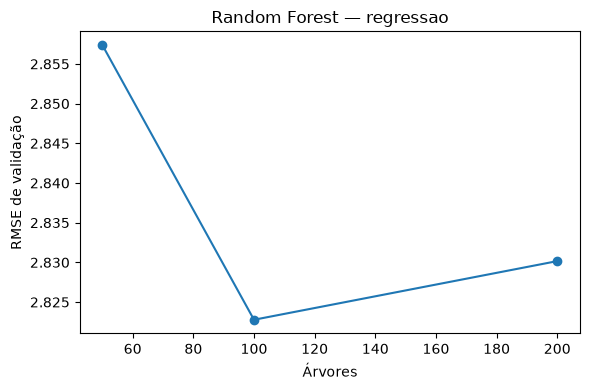

In [9]:
plt.figure(figsize=(6, 4))
tabela_grafico = tabela_arvores_rf_regressao.sort_values("arvores")
plt.plot(tabela_grafico["arvores"], tabela_grafico["RMSE_validacao"], marker="o")
plt.xlabel("Árvores")
plt.ylabel("RMSE de validação")
plt.title("Random Forest — regressao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "rf_regressao_arvores.png", dpi=150)
plt.show()


### 4.2. Random Forest — regressao: profundidade

In [10]:
linhas_profundidade_rf_regressao = []
valores_profundidade_rf_regressao = [None, 5, 10]

for profundidade in valores_profundidade_rf_regressao:
    modelo = RandomForestRegressor(n_estimators=arvores_rf_regressao, max_depth=profundidade, random_state=42)
    modelo.fit(x_ajuste, gravidade_ajuste)
    previsao_ajuste = modelo.predict(x_ajuste)
    previsao_validacao = modelo.predict(x_validacao)
    metrica_ajuste = root_mean_squared_error(gravidade_ajuste, previsao_ajuste)
    metrica_validacao = root_mean_squared_error(gravidade_validacao, previsao_validacao)
    if profundidade is None:
        valor_exibido = "Sem limite"
    else:
        valor_exibido = str(profundidade)
    linhas_profundidade_rf_regressao.append([valor_exibido, metrica_ajuste, metrica_validacao])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": gravidade_ajuste.tolist() + gravidade_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "rf_regressao"
    previsoes_configuracao["etapa"] = "profundidade"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_profundidade_rf_regressao = pd.DataFrame(linhas_profundidade_rf_regressao, columns=['profundidade', 'RMSE_ajuste', 'RMSE_validacao'])
indice_escolhido = tabela_profundidade_rf_regressao["RMSE_validacao"].idxmin()
profundidade_rf_regressao = valores_profundidade_rf_regressao[indice_escolhido]
metrica_final_validacao_rf_regressao = tabela_profundidade_rf_regressao.loc[indice_escolhido, "RMSE_validacao"]
metrica_final_ajuste_rf_regressao = tabela_profundidade_rf_regressao.loc[indice_escolhido, "RMSE_ajuste"]
display(tabela_profundidade_rf_regressao.round(6))
print("Profundidade escolhido:", profundidade_rf_regressao)
tabela_profundidade_rf_regressao.to_csv(pasta_comparacoes / "rf_regressao_profundidade.csv", index=False)


,profundidade,RMSE_ajuste,RMSE_validacao
0,Sem limite,1.087785,2.822773
1,5,5.056909,6.016645
2,10,1.232098,2.905457


Profundidade escolhido: None


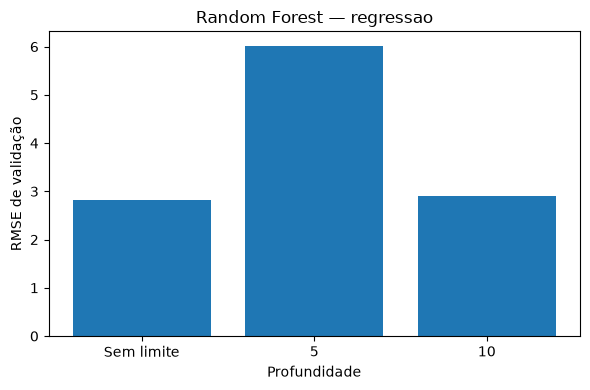

In [11]:
plt.figure(figsize=(6, 4))
plt.bar(tabela_profundidade_rf_regressao["profundidade"], tabela_profundidade_rf_regressao["RMSE_validacao"])
plt.xlabel("Profundidade")
plt.ylabel("RMSE de validação")
plt.title("Random Forest — regressao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "rf_regressao_profundidade.png", dpi=150)
plt.show()


### 4.3. Random Forest — classificacao: árvores

In [12]:
linhas_arvores_rf_classificacao = []
valores_arvores_rf_classificacao = [100, 50, 200]

for quantidade_arvores in valores_arvores_rf_classificacao:
    modelo = RandomForestClassifier(n_estimators=quantidade_arvores, random_state=42)
    modelo.fit(x_ajuste, classe_ajuste)
    previsao_ajuste = modelo.predict(x_ajuste)
    previsao_validacao = modelo.predict(x_validacao)
    metrica_ajuste = f1_score(
        classe_ajuste, previsao_ajuste, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    metrica_validacao = f1_score(
        classe_validacao, previsao_validacao, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    valor_exibido = quantidade_arvores
    linhas_arvores_rf_classificacao.append([valor_exibido, metrica_ajuste, metrica_validacao])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": classe_ajuste.tolist() + classe_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "rf_classificacao"
    previsoes_configuracao["etapa"] = "arvores"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_arvores_rf_classificacao = pd.DataFrame(linhas_arvores_rf_classificacao, columns=['arvores', 'macro_F1_ajuste', 'macro_F1_validacao'])
indice_escolhido = tabela_arvores_rf_classificacao["macro_F1_validacao"].idxmax()
arvores_rf_classificacao = valores_arvores_rf_classificacao[indice_escolhido]
display(tabela_arvores_rf_classificacao.round(6))
print("Árvores escolhido:", arvores_rf_classificacao)
tabela_arvores_rf_classificacao.to_csv(pasta_comparacoes / "rf_classificacao_arvores.csv", index=False)


,arvores,macro_F1_ajuste,macro_F1_validacao
0,100,1.0,0.815243
1,50,1.0,0.809687
2,200,1.0,0.805182


Árvores escolhido: 100


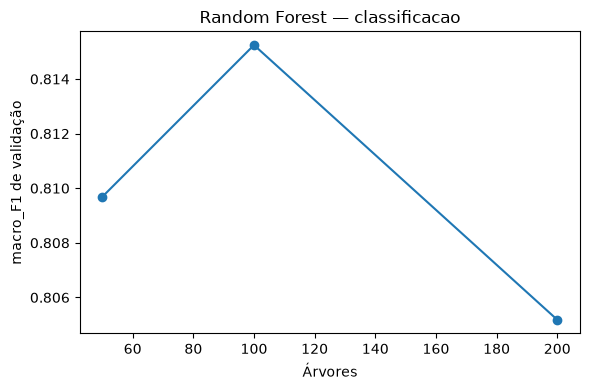

In [13]:
plt.figure(figsize=(6, 4))
tabela_grafico = tabela_arvores_rf_classificacao.sort_values("arvores")
plt.plot(tabela_grafico["arvores"], tabela_grafico["macro_F1_validacao"], marker="o")
plt.xlabel("Árvores")
plt.ylabel("macro_F1 de validação")
plt.title("Random Forest — classificacao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "rf_classificacao_arvores.png", dpi=150)
plt.show()


### 4.4. Random Forest — classificacao: profundidade

In [14]:
linhas_profundidade_rf_classificacao = []
valores_profundidade_rf_classificacao = [None, 5, 10]

for profundidade in valores_profundidade_rf_classificacao:
    modelo = RandomForestClassifier(n_estimators=arvores_rf_classificacao, max_depth=profundidade, random_state=42)
    modelo.fit(x_ajuste, classe_ajuste)
    previsao_ajuste = modelo.predict(x_ajuste)
    previsao_validacao = modelo.predict(x_validacao)
    metrica_ajuste = f1_score(
        classe_ajuste, previsao_ajuste, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    metrica_validacao = f1_score(
        classe_validacao, previsao_validacao, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    if profundidade is None:
        valor_exibido = "Sem limite"
    else:
        valor_exibido = str(profundidade)
    linhas_profundidade_rf_classificacao.append([valor_exibido, metrica_ajuste, metrica_validacao])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": classe_ajuste.tolist() + classe_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "rf_classificacao"
    previsoes_configuracao["etapa"] = "profundidade"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_profundidade_rf_classificacao = pd.DataFrame(linhas_profundidade_rf_classificacao, columns=['profundidade', 'macro_F1_ajuste', 'macro_F1_validacao'])
indice_escolhido = tabela_profundidade_rf_classificacao["macro_F1_validacao"].idxmax()
profundidade_rf_classificacao = valores_profundidade_rf_classificacao[indice_escolhido]
metrica_final_validacao_rf_classificacao = tabela_profundidade_rf_classificacao.loc[indice_escolhido, "macro_F1_validacao"]
metrica_final_ajuste_rf_classificacao = tabela_profundidade_rf_classificacao.loc[indice_escolhido, "macro_F1_ajuste"]
display(tabela_profundidade_rf_classificacao.round(6))
print("Profundidade escolhido:", profundidade_rf_classificacao)
tabela_profundidade_rf_classificacao.to_csv(pasta_comparacoes / "rf_classificacao_profundidade.csv", index=False)


,profundidade,macro_F1_ajuste,macro_F1_validacao
0,Sem limite,1.000000,0.815243
1,5,0.666133,0.598438
2,10,1.000000,0.802222


Profundidade escolhido: None


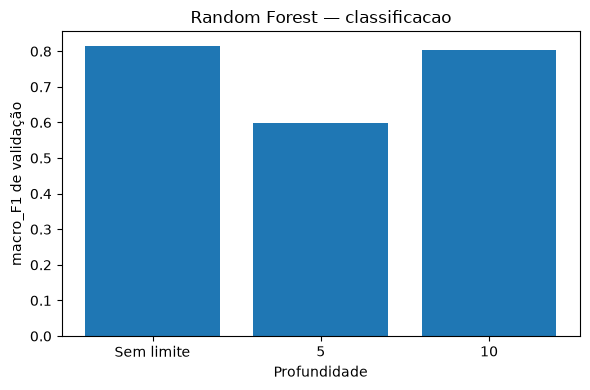

In [15]:
plt.figure(figsize=(6, 4))
plt.bar(tabela_profundidade_rf_classificacao["profundidade"], tabela_profundidade_rf_classificacao["macro_F1_validacao"])
plt.xlabel("Profundidade")
plt.ylabel("macro_F1 de validação")
plt.title("Random Forest — classificacao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "rf_classificacao_profundidade.png", dpi=150)
plt.show()


### 4.5. MLP — regressao: limite de iterações

In [16]:
linhas_iteracoes_mlp_regressao = []
valores_iteracoes_mlp_regressao = [200, 500, 1000]

for limite in valores_iteracoes_mlp_regressao:
    modelo = MLPRegressor(max_iter=limite, random_state=42)
    modelo.fit(x_ajuste_mlp, gravidade_ajuste_mlp)
    previsao_ajuste = escala_gravidade_comparacao.inverse_transform(
        modelo.predict(x_ajuste_mlp).reshape(-1, 1)
    ).ravel()
    previsao_validacao = escala_gravidade_comparacao.inverse_transform(
        modelo.predict(x_validacao_mlp).reshape(-1, 1)
    ).ravel()
    metrica_ajuste = root_mean_squared_error(gravidade_ajuste, previsao_ajuste)
    metrica_validacao = root_mean_squared_error(gravidade_validacao, previsao_validacao)
    valor_exibido = limite
    linhas_iteracoes_mlp_regressao.append([valor_exibido, metrica_ajuste, metrica_validacao, modelo.n_iter_, modelo.n_iter_ >= modelo.max_iter])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": gravidade_ajuste.tolist() + gravidade_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "mlp_regressao"
    previsoes_configuracao["etapa"] = "iteracoes"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_iteracoes_mlp_regressao = pd.DataFrame(linhas_iteracoes_mlp_regressao, columns=['iteracoes', 'RMSE_ajuste', 'RMSE_validacao', 'iteracoes_realizadas', 'atingiu_limite'])
indice_escolhido = tabela_iteracoes_mlp_regressao["RMSE_validacao"].idxmin()
iteracoes_mlp_regressao = valores_iteracoes_mlp_regressao[indice_escolhido]
display(tabela_iteracoes_mlp_regressao.round(6))
print("Limite de iterações escolhido:", iteracoes_mlp_regressao)
tabela_iteracoes_mlp_regressao.to_csv(pasta_comparacoes / "mlp_regressao_iteracoes.csv", index=False)


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,iteracoes,RMSE_ajuste,RMSE_validacao,iteracoes_realizadas,atingiu_limite
0,200,4.253547,4.889436,200,True
1,500,3.815697,4.423352,272,False
2,1000,3.815697,4.423352,272,False


Limite de iterações escolhido: 500


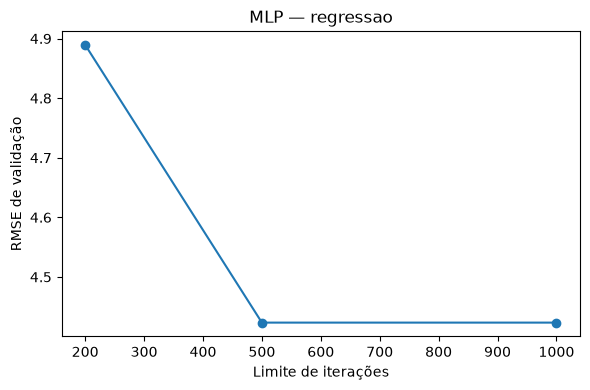

In [17]:
plt.figure(figsize=(6, 4))
tabela_grafico = tabela_iteracoes_mlp_regressao.sort_values("iteracoes")
plt.plot(tabela_grafico["iteracoes"], tabela_grafico["RMSE_validacao"], marker="o")
plt.xlabel("Limite de iterações")
plt.ylabel("RMSE de validação")
plt.title("MLP — regressao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "mlp_regressao_iteracoes.png", dpi=150)
plt.show()


### 4.6. MLP — regressao: neurônios

In [18]:
linhas_neuronios_mlp_regressao = []
valores_neuronios_mlp_regressao = [100, 50, 150]

for neuronios in valores_neuronios_mlp_regressao:
    modelo = MLPRegressor(hidden_layer_sizes=(neuronios,), max_iter=iteracoes_mlp_regressao, random_state=42)
    modelo.fit(x_ajuste_mlp, gravidade_ajuste_mlp)
    previsao_ajuste = escala_gravidade_comparacao.inverse_transform(
        modelo.predict(x_ajuste_mlp).reshape(-1, 1)
    ).ravel()
    previsao_validacao = escala_gravidade_comparacao.inverse_transform(
        modelo.predict(x_validacao_mlp).reshape(-1, 1)
    ).ravel()
    metrica_ajuste = root_mean_squared_error(gravidade_ajuste, previsao_ajuste)
    metrica_validacao = root_mean_squared_error(gravidade_validacao, previsao_validacao)
    valor_exibido = neuronios
    linhas_neuronios_mlp_regressao.append([valor_exibido, metrica_ajuste, metrica_validacao, modelo.n_iter_, modelo.n_iter_ >= modelo.max_iter])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": gravidade_ajuste.tolist() + gravidade_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "mlp_regressao"
    previsoes_configuracao["etapa"] = "neuronios"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_neuronios_mlp_regressao = pd.DataFrame(linhas_neuronios_mlp_regressao, columns=['neuronios', 'RMSE_ajuste', 'RMSE_validacao', 'iteracoes_realizadas', 'atingiu_limite'])
indice_escolhido = tabela_neuronios_mlp_regressao["RMSE_validacao"].idxmin()
neuronios_mlp_regressao = valores_neuronios_mlp_regressao[indice_escolhido]
metrica_final_validacao_mlp_regressao = tabela_neuronios_mlp_regressao.loc[indice_escolhido, "RMSE_validacao"]
metrica_final_ajuste_mlp_regressao = tabela_neuronios_mlp_regressao.loc[indice_escolhido, "RMSE_ajuste"]
display(tabela_neuronios_mlp_regressao.round(6))
print("Neurônios escolhido:", neuronios_mlp_regressao)
tabela_neuronios_mlp_regressao.to_csv(pasta_comparacoes / "mlp_regressao_neuronios.csv", index=False)


,neuronios,RMSE_ajuste,RMSE_validacao,iteracoes_realizadas,atingiu_limite
0,100,3.815697,4.423352,272,False
1,50,3.760110,4.328586,405,False
2,150,3.191107,3.830192,351,False


Neurônios escolhido: 150


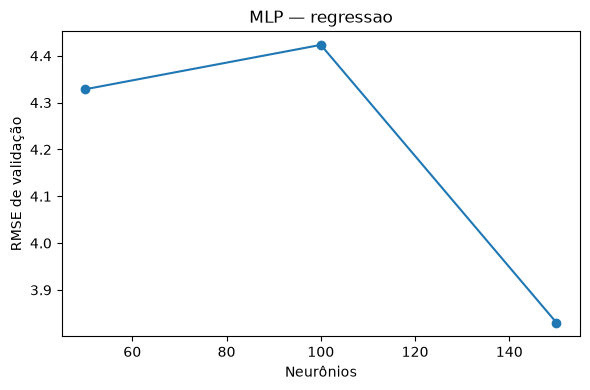

In [19]:
plt.figure(figsize=(6, 4))
tabela_grafico = tabela_neuronios_mlp_regressao.sort_values("neuronios")
plt.plot(tabela_grafico["neuronios"], tabela_grafico["RMSE_validacao"], marker="o")
plt.xlabel("Neurônios")
plt.ylabel("RMSE de validação")
plt.title("MLP — regressao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "mlp_regressao_neuronios.png", dpi=150)
plt.show()


### 4.7. MLP — classificacao: limite de iterações

In [20]:
linhas_iteracoes_mlp_classificacao = []
valores_iteracoes_mlp_classificacao = [200, 500, 1000]

for limite in valores_iteracoes_mlp_classificacao:
    modelo = MLPClassifier(max_iter=limite, random_state=42)
    modelo.fit(x_ajuste_mlp, classe_ajuste)
    previsao_ajuste = modelo.predict(x_ajuste_mlp)
    previsao_validacao = modelo.predict(x_validacao_mlp)
    metrica_ajuste = f1_score(
        classe_ajuste, previsao_ajuste, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    metrica_validacao = f1_score(
        classe_validacao, previsao_validacao, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    valor_exibido = limite
    linhas_iteracoes_mlp_classificacao.append([valor_exibido, metrica_ajuste, metrica_validacao, modelo.n_iter_, modelo.n_iter_ >= modelo.max_iter])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": classe_ajuste.tolist() + classe_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "mlp_classificacao"
    previsoes_configuracao["etapa"] = "iteracoes"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_iteracoes_mlp_classificacao = pd.DataFrame(linhas_iteracoes_mlp_classificacao, columns=['iteracoes', 'macro_F1_ajuste', 'macro_F1_validacao', 'iteracoes_realizadas', 'atingiu_limite'])
indice_escolhido = tabela_iteracoes_mlp_classificacao["macro_F1_validacao"].idxmax()
iteracoes_mlp_classificacao = valores_iteracoes_mlp_classificacao[indice_escolhido]
display(tabela_iteracoes_mlp_classificacao.round(6))
print("Limite de iterações escolhido:", iteracoes_mlp_classificacao)
tabela_iteracoes_mlp_classificacao.to_csv(pasta_comparacoes / "mlp_classificacao_iteracoes.csv", index=False)


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,iteracoes,macro_F1_ajuste,macro_F1_validacao,iteracoes_realizadas,atingiu_limite
0,200,0.593936,0.560847,200,True
1,500,0.868363,0.815605,500,True
2,1000,0.929672,0.871964,1000,True


Limite de iterações escolhido: 1000


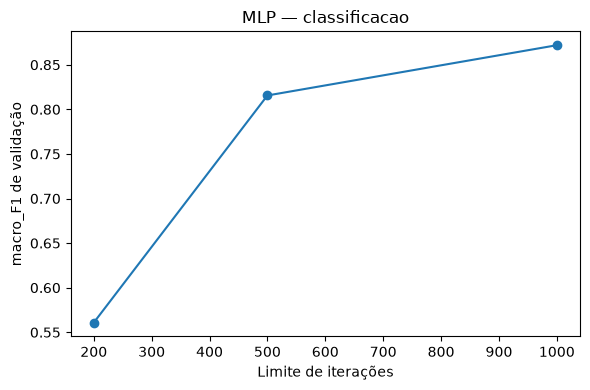

In [21]:
plt.figure(figsize=(6, 4))
tabela_grafico = tabela_iteracoes_mlp_classificacao.sort_values("iteracoes")
plt.plot(tabela_grafico["iteracoes"], tabela_grafico["macro_F1_validacao"], marker="o")
plt.xlabel("Limite de iterações")
plt.ylabel("macro_F1 de validação")
plt.title("MLP — classificacao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "mlp_classificacao_iteracoes.png", dpi=150)
plt.show()


### 4.8. MLP — classificacao: neurônios

In [22]:
linhas_neuronios_mlp_classificacao = []
valores_neuronios_mlp_classificacao = [100, 50, 150]

for neuronios in valores_neuronios_mlp_classificacao:
    modelo = MLPClassifier(hidden_layer_sizes=(neuronios,), max_iter=iteracoes_mlp_classificacao, random_state=42)
    modelo.fit(x_ajuste_mlp, classe_ajuste)
    previsao_ajuste = modelo.predict(x_ajuste_mlp)
    previsao_validacao = modelo.predict(x_validacao_mlp)
    metrica_ajuste = f1_score(
        classe_ajuste, previsao_ajuste, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    metrica_validacao = f1_score(
        classe_validacao, previsao_validacao, labels=[1, 2, 3, 4], average="macro", zero_division=0
    )
    valor_exibido = neuronios
    linhas_neuronios_mlp_classificacao.append([valor_exibido, metrica_ajuste, metrica_validacao, modelo.n_iter_, modelo.n_iter_ >= modelo.max_iter])

    previsoes_configuracao = pd.DataFrame({
        "id": dados_ajuste["id"].tolist() + dados_validacao["id"].tolist(),
        "conjunto": ["ajuste"] * len(dados_ajuste) + ["validacao"] * len(dados_validacao),
        "real": classe_ajuste.tolist() + classe_validacao.tolist(),
        "previsto": previsao_ajuste.tolist() + previsao_validacao.tolist(),
    })
    previsoes_configuracao["modelo"] = "mlp_classificacao"
    previsoes_configuracao["etapa"] = "neuronios"
    previsoes_configuracao["valor_parametro"] = str(valor_exibido)
    previsoes_comparacoes.append(previsoes_configuracao)

tabela_neuronios_mlp_classificacao = pd.DataFrame(linhas_neuronios_mlp_classificacao, columns=['neuronios', 'macro_F1_ajuste', 'macro_F1_validacao', 'iteracoes_realizadas', 'atingiu_limite'])
indice_escolhido = tabela_neuronios_mlp_classificacao["macro_F1_validacao"].idxmax()
neuronios_mlp_classificacao = valores_neuronios_mlp_classificacao[indice_escolhido]
metrica_final_validacao_mlp_classificacao = tabela_neuronios_mlp_classificacao.loc[indice_escolhido, "macro_F1_validacao"]
metrica_final_ajuste_mlp_classificacao = tabela_neuronios_mlp_classificacao.loc[indice_escolhido, "macro_F1_ajuste"]
display(tabela_neuronios_mlp_classificacao.round(6))
print("Neurônios escolhido:", neuronios_mlp_classificacao)
tabela_neuronios_mlp_classificacao.to_csv(pasta_comparacoes / "mlp_classificacao_neuronios.csv", index=False)


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,neuronios,macro_F1_ajuste,macro_F1_validacao,iteracoes_realizadas,atingiu_limite
0,100,0.929672,0.871964,1000,True
1,50,0.883165,0.879295,1000,True
2,150,0.942315,0.874779,1000,True


Neurônios escolhido: 50


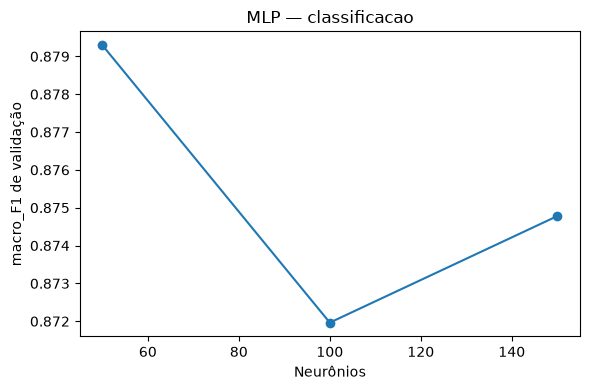

In [23]:
plt.figure(figsize=(6, 4))
tabela_grafico = tabela_neuronios_mlp_classificacao.sort_values("neuronios")
plt.plot(tabela_grafico["neuronios"], tabela_grafico["macro_F1_validacao"], marker="o")
plt.xlabel("Neurônios")
plt.ylabel("macro_F1 de validação")
plt.title("MLP — classificacao")
plt.tight_layout()
plt.savefig(pasta_comparacoes / "mlp_classificacao_neuronios.png", dpi=150)
plt.show()


### Resumo das configurações escolhidas

In [24]:
selecao_parametros = pd.DataFrame([
    ["rf_regressao", "RMSE", "n_estimators", arvores_rf_regressao, "max_depth",
     str(profundidade_rf_regressao),
     tabela_arvores_rf_regressao.loc[0, "RMSE_validacao"],
     metrica_final_validacao_rf_regressao, metrica_final_ajuste_rf_regressao,
     tabela_arvores_rf_regressao.loc[0, "RMSE_validacao"] - metrica_final_validacao_rf_regressao],

    ["rf_classificacao", "macro_F1", "n_estimators", arvores_rf_classificacao, "max_depth",
     str(profundidade_rf_classificacao),
     tabela_arvores_rf_classificacao.loc[0, "macro_F1_validacao"],
     metrica_final_validacao_rf_classificacao, metrica_final_ajuste_rf_classificacao,
     metrica_final_validacao_rf_classificacao - tabela_arvores_rf_classificacao.loc[0, "macro_F1_validacao"]],

    ["mlp_regressao", "RMSE", "max_iter", iteracoes_mlp_regressao, "hidden_layer_sizes",
     str(neuronios_mlp_regressao),
     tabela_iteracoes_mlp_regressao.loc[0, "RMSE_validacao"],
     metrica_final_validacao_mlp_regressao, metrica_final_ajuste_mlp_regressao,
     tabela_iteracoes_mlp_regressao.loc[0, "RMSE_validacao"] - metrica_final_validacao_mlp_regressao],

    ["mlp_classificacao", "macro_F1", "max_iter", iteracoes_mlp_classificacao, "hidden_layer_sizes",
     str(neuronios_mlp_classificacao),
     tabela_iteracoes_mlp_classificacao.loc[0, "macro_F1_validacao"],
     metrica_final_validacao_mlp_classificacao, metrica_final_ajuste_mlp_classificacao,
     metrica_final_validacao_mlp_classificacao - tabela_iteracoes_mlp_classificacao.loc[0, "macro_F1_validacao"]],
], columns=[
    "modelo", "metrica", "parametro_1", "valor_1", "parametro_2", "valor_2",
    "validacao_inicial", "validacao_escolhida", "ajuste_escolhido", "melhoria_absoluta",
])

display(selecao_parametros.round(6))
selecao_parametros.to_csv(pasta_comparacoes / "selecao_parametros.csv", index=False)

predicoes_comparacoes = pd.concat(previsoes_comparacoes, ignore_index=True)
predicoes_comparacoes.to_csv(pasta_comparacoes / "predicoes_comparacoes.csv", index=False)

divisao_ajuste = dados_ajuste[["id"]].copy()
divisao_ajuste["conjunto"] = "ajuste"
divisao_validacao_registro = dados_validacao[["id"]].copy()
divisao_validacao_registro["conjunto"] = "validacao"
divisao_teste_registro = dados_teste[["id"]].copy()
divisao_teste_registro["conjunto"] = "teste"
divisoes_registradas = pd.concat(
    [divisao_ajuste, divisao_validacao_registro, divisao_teste_registro],
    ignore_index=True,
)
divisoes_registradas.to_csv(pasta_comparacoes / "divisoes.csv", index=False)


,modelo,metrica,parametro_1,valor_1,parametro_2,valor_2,validacao_inicial,validacao_escolhida,ajuste_escolhido,melhoria_absoluta
0,rf_regressao,RMSE,n_estimators,100,max_depth,None,2.822773,2.822773,1.087785,0.000000
1,rf_classificacao,macro_F1,n_estimators,100,max_depth,None,0.815243,0.815243,1.000000,0.000000
2,mlp_regressao,RMSE,max_iter,500,hidden_layer_sizes,150,4.889436,3.830192,3.191107,1.059244
3,mlp_classificacao,macro_F1,max_iter,1000,hidden_layer_sizes,50,0.560847,0.879295,0.883165,0.318448


## 5. Preparar as escalas para o treinamento final

In [25]:
escala_sinais = StandardScaler()

x_treino_mlp = escala_sinais.fit_transform(x_treino)
x_teste_mlp = escala_sinais.transform(x_teste)


### Preparar também a gravidade para o regressor MLP

In [26]:
escala_gravidade = StandardScaler()

gravidade_treino_mlp = escala_gravidade.fit_transform(
    dados_treino[["gravidade"]]
)
gravidade_treino_mlp = gravidade_treino_mlp.ravel()


## 6. Treinar e prever com Random Forest

In [27]:
rf_regressao = RandomForestRegressor(
    n_estimators=arvores_rf_regressao,
    max_depth=profundidade_rf_regressao,
    random_state=42,
)
rf_regressao.fit(x_treino, gravidade_treino)

rf_gravidade_treino = rf_regressao.predict(x_treino)
rf_gravidade_teste = rf_regressao.predict(x_teste)


In [28]:
rf_classificacao = RandomForestClassifier(
    n_estimators=arvores_rf_classificacao,
    max_depth=profundidade_rf_classificacao,
    random_state=42,
)
rf_classificacao.fit(x_treino, classe_treino)

rf_classe_treino = rf_classificacao.predict(x_treino)
rf_classe_teste = rf_classificacao.predict(x_teste)


## 7. Treinar e prever com MLP

In [ ]:
mlp_regressao = MLPRegressor(
    hidden_layer_sizes=(neuronios_mlp_regressao,),
    max_iter=iteracoes_mlp_regressao,
    random_state=42,
)
mlp_regressao.fit(x_treino_mlp, gravidade_treino_mlp)

mlp_gravidade_treino_padronizada = mlp_regressao.predict(x_treino_mlp)
mlp_gravidade_teste_padronizada = mlp_regressao.predict(x_teste_mlp)

mlp_gravidade_treino = escala_gravidade.inverse_transform(
    mlp_gravidade_treino_padronizada.reshape(-1, 1)
).ravel()

mlp_gravidade_teste = escala_gravidade.inverse_transform(
    mlp_gravidade_teste_padronizada.reshape(-1, 1)
).ravel()

print("Iterações do regressor final:", mlp_regressao.n_iter_)


Iterações do regressor final: 294


In [30]:
mlp_classificacao = MLPClassifier(
    hidden_layer_sizes=(neuronios_mlp_classificacao,),
    max_iter=iteracoes_mlp_classificacao,
    random_state=42,
)
mlp_classificacao.fit(x_treino_mlp, classe_treino)

mlp_classe_treino = mlp_classificacao.predict(x_treino_mlp)
mlp_classe_teste = mlp_classificacao.predict(x_teste_mlp)

print("Iterações do classificador final:", mlp_classificacao.n_iter_)


Iterações do classificador final: 1000


D:\Faculdade\SI\Tarefa2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


## 8. Construir referências simples

In [31]:
gravidade_media = gravidade_treino.mean()
classe_mais_frequente = classe_treino.mode().iloc[0]

referencia_gravidade = np.full(len(dados_teste), gravidade_media)
referencia_classe = np.full(len(dados_teste), classe_mais_frequente)

print("Gravidade média do treinamento:", gravidade_media)
print("Classe mais frequente do treinamento:", classe_mais_frequente)


Gravidade média do treinamento: 41.617255336666666
Classe mais frequente do treinamento: 2


## 9. Avaliar a regressão

In [32]:
metricas_regressao = pd.DataFrame([
    ["Random Forest", "treino",
     root_mean_squared_error(gravidade_treino, rf_gravidade_treino),
     mean_absolute_error(gravidade_treino, rf_gravidade_treino),
     r2_score(gravidade_treino, rf_gravidade_treino)],

    ["Random Forest", "teste",
     root_mean_squared_error(gravidade_teste, rf_gravidade_teste),
     mean_absolute_error(gravidade_teste, rf_gravidade_teste),
     r2_score(gravidade_teste, rf_gravidade_teste)],

    ["MLP", "treino",
     root_mean_squared_error(gravidade_treino, mlp_gravidade_treino),
     mean_absolute_error(gravidade_treino, mlp_gravidade_treino),
     r2_score(gravidade_treino, mlp_gravidade_treino)],

    ["MLP", "teste",
     root_mean_squared_error(gravidade_teste, mlp_gravidade_teste),
     mean_absolute_error(gravidade_teste, mlp_gravidade_teste),
     r2_score(gravidade_teste, mlp_gravidade_teste)],

    ["Referência: média", "teste",
     root_mean_squared_error(gravidade_teste, referencia_gravidade),
     mean_absolute_error(gravidade_teste, referencia_gravidade),
     r2_score(gravidade_teste, referencia_gravidade)],
], columns=["modelo", "conjunto", "RMSE", "MAE", "R2"])

display(metricas_regressao.round(4))


,modelo,conjunto,RMSE,MAE,R2
0,Random Forest,treino,0.9860,0.5959,0.9965
1,Random Forest,teste,2.4656,1.5274,0.9770
2,MLP,treino,3.2150,2.2991,0.9628
3,MLP,teste,3.2188,2.4163,0.9609
4,Referência: média,teste,16.2965,13.1859,-0.0034


## 10. Avaliar a classificação

In [33]:
metricas_classificacao = pd.DataFrame([
    ["Random Forest", "treino",
     accuracy_score(classe_treino, rf_classe_treino),
     f1_score(classe_treino, rf_classe_treino, average="macro", zero_division=0),
     balanced_accuracy_score(classe_treino, rf_classe_treino)],

    ["Random Forest", "teste",
     accuracy_score(classe_teste, rf_classe_teste),
     f1_score(classe_teste, rf_classe_teste, average="macro", zero_division=0),
     balanced_accuracy_score(classe_teste, rf_classe_teste)],

    ["MLP", "treino",
     accuracy_score(classe_treino, mlp_classe_treino),
     f1_score(classe_treino, mlp_classe_treino, average="macro", zero_division=0),
     balanced_accuracy_score(classe_treino, mlp_classe_treino)],

    ["MLP", "teste",
     accuracy_score(classe_teste, mlp_classe_teste),
     f1_score(classe_teste, mlp_classe_teste, average="macro", zero_division=0),
     balanced_accuracy_score(classe_teste, mlp_classe_teste)],

    ["Referência: classe mais frequente", "teste",
     accuracy_score(classe_teste, referencia_classe),
     f1_score(classe_teste, referencia_classe, average="macro", zero_division=0),
     balanced_accuracy_score(classe_teste, referencia_classe)],
], columns=["modelo", "conjunto", "acuracia", "macro_F1", "acuracia_balanceada"])

display(metricas_classificacao.round(4))


,modelo,conjunto,acuracia,macro_F1,acuracia_balanceada
0,Random Forest,treino,1.0000,1.0000,1.0000
1,Random Forest,teste,0.9033,0.8433,0.7899
2,MLP,treino,0.9083,0.9014,0.8836
3,MLP,teste,0.8867,0.8191,0.8091
4,Referência: classe mais frequente,teste,0.5533,0.1781,0.2500


### Examinar cada classe

In [34]:
relatorio_rf = classification_report(
    classe_teste, rf_classe_teste,
    labels=[1, 2, 3, 4],
    output_dict=True,
    zero_division=0,
)
relatorio_mlp = classification_report(
    classe_teste, mlp_classe_teste,
    labels=[1, 2, 3, 4],
    output_dict=True,
    zero_division=0,
)

tabela_classes_rf = pd.DataFrame(relatorio_rf).transpose()
tabela_classes_rf = tabela_classes_rf.loc[["1", "2", "3", "4"]].copy()
tabela_classes_rf.insert(0, "modelo", "Random Forest")

tabela_classes_mlp = pd.DataFrame(relatorio_mlp).transpose()
tabela_classes_mlp = tabela_classes_mlp.loc[["1", "2", "3", "4"]].copy()
tabela_classes_mlp.insert(0, "modelo", "MLP")

metricas_por_classe = pd.concat([tabela_classes_rf, tabela_classes_mlp])
metricas_por_classe.index.name = "classe"

display(metricas_por_classe.round(4))


,modelo,precision,recall,f1-score,support
classe,,,,,
1,Random Forest,0.9767,0.8936,0.9333,47.0
2,Random Forest,0.8804,0.9759,0.9257,166.0
3,Random Forest,0.9143,0.7901,0.8477,81.0
4,Random Forest,1.0000,0.5000,0.6667,6.0
1,MLP,0.8372,0.7660,0.8000,47.0
2,MLP,0.8864,0.9398,0.9123,166.0
3,MLP,0.9333,0.8642,0.8974,81.0
4,MLP,0.6667,0.6667,0.6667,6.0


## 11. Visualizar os erros

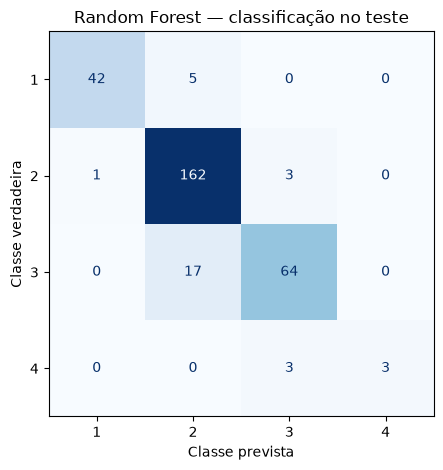

In [35]:
ConfusionMatrixDisplay.from_predictions(
    classe_teste,
    rf_classe_teste,
    labels=[1, 2, 3, 4],
    cmap="Blues",
    colorbar=False,
)
plt.title("Random Forest — classificação no teste")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.tight_layout()
plt.savefig(pasta_resultados / "confusao_rf.png", dpi=150)
plt.show()


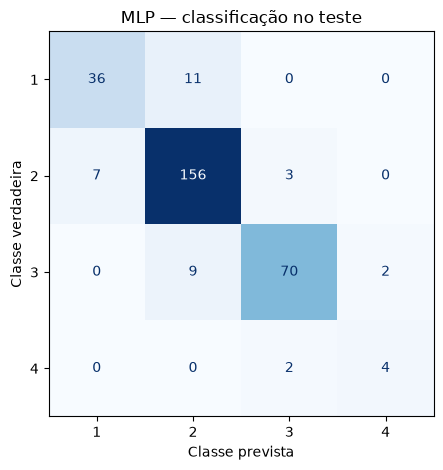

In [36]:
ConfusionMatrixDisplay.from_predictions(
    classe_teste,
    mlp_classe_teste,
    labels=[1, 2, 3, 4],
    cmap="Blues",
    colorbar=False,
)
plt.title("MLP — classificação no teste")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.tight_layout()
plt.savefig(pasta_resultados / "confusao_mlp.png", dpi=150)
plt.show()


### Comparar gravidade real e prevista

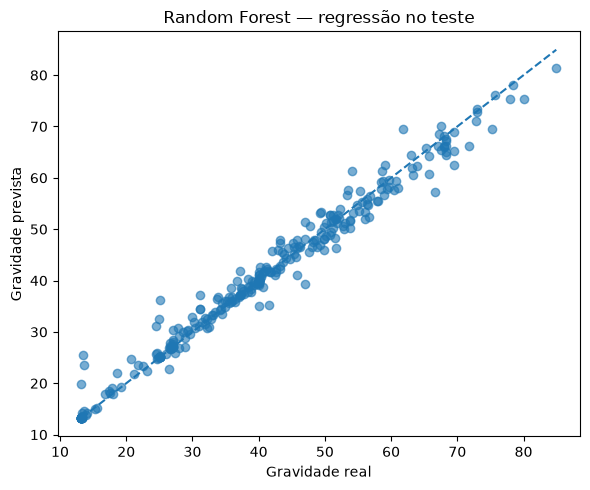

In [37]:
plt.figure(figsize=(6, 5))
plt.scatter(gravidade_teste, rf_gravidade_teste, alpha=0.6)
plt.plot(
    [gravidade_teste.min(), gravidade_teste.max()],
    [gravidade_teste.min(), gravidade_teste.max()],
    "--",
)
plt.xlabel("Gravidade real")
plt.ylabel("Gravidade prevista")
plt.title("Random Forest — regressão no teste")
plt.tight_layout()
plt.savefig(pasta_resultados / "regressao_rf.png", dpi=150)
plt.show()


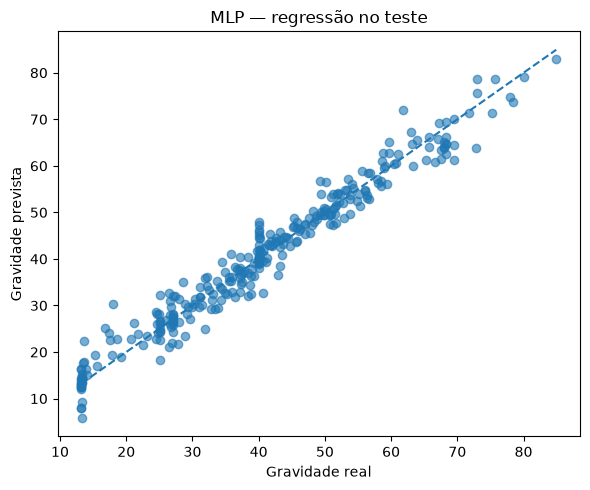

In [38]:
plt.figure(figsize=(6, 5))
plt.scatter(gravidade_teste, mlp_gravidade_teste, alpha=0.6)
plt.plot(
    [gravidade_teste.min(), gravidade_teste.max()],
    [gravidade_teste.min(), gravidade_teste.max()],
    "--",
)
plt.xlabel("Gravidade real")
plt.ylabel("Gravidade prevista")
plt.title("MLP — regressão no teste")
plt.tight_layout()
plt.savefig(pasta_resultados / "regressao_mlp.png", dpi=150)
plt.show()


## 12. Salvar as tabelas e as previsões

In [39]:
metricas_regressao.to_csv(pasta_resultados / "metricas_regressao.csv", index=False)
metricas_classificacao.to_csv(pasta_resultados / "metricas_classificacao.csv", index=False)
metricas_por_classe.to_csv(pasta_resultados / "metricas_por_classe.csv")

predicoes_teste = dados_teste[["id", "gravidade", "classe"]].copy()
predicoes_teste["rf_gravidade"] = rf_gravidade_teste
predicoes_teste["rf_classe"] = rf_classe_teste
predicoes_teste["mlp_gravidade"] = mlp_gravidade_teste
predicoes_teste["mlp_classe"] = mlp_classe_teste
predicoes_teste["referencia_gravidade"] = referencia_gravidade
predicoes_teste["referencia_classe"] = referencia_classe

predicoes_teste.to_csv(pasta_resultados / "predicoes_teste.csv", index=False)
display(predicoes_teste.head())


predicoes_treino = dados_treino[["id", "gravidade", "classe"]].copy()
predicoes_treino["rf_gravidade"] = rf_gravidade_treino
predicoes_treino["rf_classe"] = rf_classe_treino
predicoes_treino["mlp_gravidade"] = mlp_gravidade_treino
predicoes_treino["mlp_classe"] = mlp_classe_treino
predicoes_treino["referencia_gravidade"] = gravidade_media
predicoes_treino["referencia_classe"] = classe_mais_frequente
predicoes_treino.to_csv(pasta_resultados / "predicoes_treino.csv", index=False)

ajustes_finais_mlp = pd.DataFrame([
    ["mlp_regressao", iteracoes_mlp_regressao, neuronios_mlp_regressao,
     mlp_regressao.n_iter_, mlp_regressao.n_iter_ >= mlp_regressao.max_iter],
    ["mlp_classificacao", iteracoes_mlp_classificacao, neuronios_mlp_classificacao,
     mlp_classificacao.n_iter_, mlp_classificacao.n_iter_ >= mlp_classificacao.max_iter],
], columns=["modelo", "limite_iteracoes", "neuronios", "iteracoes_realizadas", "atingiu_limite"])
ajustes_finais_mlp.to_csv(pasta_resultados / "ajustes_finais_mlp.csv", index=False)
display(ajustes_finais_mlp)


,id,gravidade,classe,rf_gravidade,rf_classe,mlp_gravidade,mlp_classe,referencia_gravidade,referencia_classe
1044,1045,39.762449,2,39.296228,2,41.672318,2,41.617255,2
74,75,37.134587,2,37.255999,2,38.007741,2,41.617255,2
673,674,20.735624,1,24.635159,2,22.906995,2,41.617255,2
277,278,30.165631,2,31.952430,2,30.225250,2,41.617255,2
1488,1489,49.456820,2,49.533747,2,50.089846,2,41.617255,2


,modelo,limite_iteracoes,neuronios,iteracoes_realizadas,atingiu_limite
0,mlp_regressao,500,150,294,False
1,mlp_classificacao,1000,50,1000,True
